In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# 1) The simulation code

In [12]:
import numpy as np

def compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=None):


    # 16 types Pop[TR,VR]
    Pop = np.zeros((4,4), dtype=np.int64)

    
    Pop[0,:] = PopSize//4

    # environment favours VR = 0 → 1 → 2 → 3 → 0 → ...
    Hcycle = [
        np.array([0,1,0,0]),
        np.array([0,0,1,0]),
        np.array([0,0,0,1])
    ]
    Hindex = 0
    H = Hcycle[Hindex]

    next_switch = tau/dt

    freqTR=[]
    AvH=[]
    for k in range(steps):

        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % 3
            H = Hcycle[Hindex]
            next_switch += tau/dt

        # ---- SELECTION ----
        # growth factors for each VR
        w = np.exp(H * dt)  # size 4 vector

        # weighted population
        weighted = Pop * w  # broadcasting over VR
        total_fit = weighted.sum()

        # normalized reproduction probability per (TR,VR)
        P_repro = weighted / total_fit

        # sample next generation
        counts = P_repro.reshape(-1)
        new_counts = np.random.multinomial(PopSize, counts)
        Pop = new_counts.reshape(4,4)

        # ---- TR mutation (sequence mutation) ----
        # each TR mutates with rate mu to uniform TR
        for vr in range(4):
            for tr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number mutating
                m = np.random.binomial(count, mu*dt)
                if m > 0:
                    Pop[tr,vr] -= m
                    # redistribute among TR=0..3
                    redist = np.random.multinomial(m, [1/4]*4)
                    Pop[:,vr] += redist

        # ---- VR switching (genotype change using DGR(TR)) ----
        for tr in range(4):
            for vr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number switching genotype
                s = np.random.binomial(count, nu*dt)
                if s == 0:
                    continue

                Pop[tr,vr] -= s
                if tr!=0:
                    Pop[tr,tr]+=s
                else:
                    Pop[tr,:]+=np.random.multinomial(s, [1/4]*4)

        # statistics
        freqTR.append(Pop[:,:] / PopSize)
        AvH.append(np.sum(Pop*H/PopSize))
    return np.array(freqTR)[3*int(tau/dt):],np.array(AvH)[3*int(tau/dt):]


In [13]:
tau =20
dt = 1e-2
mu = 1e-5
nu = 1/tau
Q=4

res,AvH = compete_four_pops_multinomial( tau, mu, nu,  dt, PopSize=10**12,steps=int(tau/dt*10))
T=np.arange(len(res[:,0,0]))*dt
x=T[T<tau]
f=res[T<tau,:,:] #Only the window at fixed environment

# I - The solving of the matrix problem to get the initial conditions

In [14]:
def compute_lambda(dt,nu,tau,Q):
    x=np.arange(int(tau/dt))*dt
    
    def solve_n0_n1(T, nu,Q=4, tol=1e-12):
        """
        Solve the 2x2 linear system for n0(t), n1(t) with arbitrary initial conditions.
        T : numpy array of times (shape (nt,))
        nu, Q : parameters
        n0_init, n1_init : initial values at t=0
        Returns (n0, n1) numpy arrays of same shape as T.
        """
    
        # constants
        Delta = np.sqrt((1.0 - nu)**2 + 4.0 * nu / Q)
        lam_p = (1.0 - nu + Delta) / 2.0
        lam_m = (1.0 - nu - Delta) / 2.0
    
        a11 = 1.0 - nu * (Q - 1.0) / Q
        a12 = nu / Q
    
        # eigenvector ratios v1/v0
        r_p = (lam_p - a11) / a12
        r_m = (lam_m - a11) / a12
    
        denom = (r_p - r_m)
    
        n0_init=r_p/(Q-1)/(1+r_p)
        n1_init=1-n0_init
        # handle generic (non-degenerate) case
        if abs(denom) > tol:
            C_p = (n1_init - r_m * n0_init) / denom
            C_m = (r_p * n0_init - n1_init) / denom
    
            n0 = C_p * np.exp(lam_p * T) + C_m * np.exp(lam_m * T)
            n1 = C_p * r_p * np.exp(lam_p * T) + C_m * r_m * np.exp(lam_m * T)
    
            return n0, n1
    
    sol_0,sol_1=solve_n0_n1(x, nu)
    lamb=sol_0/(sol_0+sol_1)
    return lamb

In [15]:
import numpy as np

def compute_fractions(lamb, dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM):
    """
    Compute final values of the fractions f_NM, f_NT, f_TT, f_TM
    using the integral formulas with exponentials inside the integral.
    """

    lamb = np.asarray(lamb)
    N = len(lamb)
    t = np.arange(N) * dt
    Lambda = np.cumsum(lamb) * dt

    # ---------------- f_TM ----------------
    I_TM = np.zeros(N)
    for i in range(1, N):
        # exponential factor inside the sum
        I_TM[i] = np.sum(np.exp(nu * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * (1 - lamb[:i])) * dt
    f_TM = f0_TM * np.exp(-nu*t - Lambda) + (mu/Q) * I_TM

    # ---------------- f_NT ----------------
    I_NT = np.zeros(N)
    for i in range(1, N):
        I_NT[i] = np.sum(np.exp((-1+nu) * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * lamb[:i]) * dt
    f_NT = f0_NT * np.exp((1-nu)*t - Lambda) + (mu*(Q-2)/Q) * I_NT

    # ---------------- f_TT ----------------
    I_TT = np.zeros(N)
    for i in range(1, N):
        I_TT[i] = np.sum(np.exp((-t[:i] + t[i]) + (Lambda[:i] - Lambda[i])) * (mu/Q*lamb[:i] + nu*f_TM[:i])) * dt
    f_TT = f0_TT * np.exp(t - Lambda) +  I_TT

    # ---------------- f_NM ----------------
    I_NM = np.zeros(N)
    for i in range(1, N):
        I_NM[i] = np.sum(np.exp(Lambda[:i] - Lambda[i]) * (mu*(Q-2)/Q*(1-lamb[:i]) + nu*f_NT[:i])) * dt
    f_NM = f0_NM * np.exp(-Lambda) +  I_NM

    return f_NM[-1], f_NT[-1], f_TT[-1], f_TM[-1]


In [16]:
lamb=compute_lambda(dt,nu,tau,Q)

c = np.array( compute_fractions(lamb, dt, mu, nu, Q, 0,0,0,0) )

M = np.zeros((4,4))

for i in range(4):
    e = np.zeros(4)
    e[i] = 1.0
    M[:,i] = np.array( compute_fractions(lamb, dt, mu, nu, Q, *e) ) - c # *e allows to unpack the CI

R = np.array([
    [1/(Q-2), 1/(Q-2), 1,           (Q-2)/(Q-1)],
    [0,       0,       0,           (Q-2)/(Q-1)],
    [1/(Q-2), 0,       0,           0],
    [0,       1/(Q-2), 0,           0]
], dtype=float)

A = R @ M
d = R @ c

I = np.eye(4)
b_star = np.linalg.solve(I - A, d) #computation of b* (see SM), the initial conditions
print(b_star)
print('NM, NT, TT, TM')

[4.60444561e-04 6.06052525e-08 2.17833364e-06 4.22705087e-05]
NM, NT, TT, TM


# II - Check the TR=A population

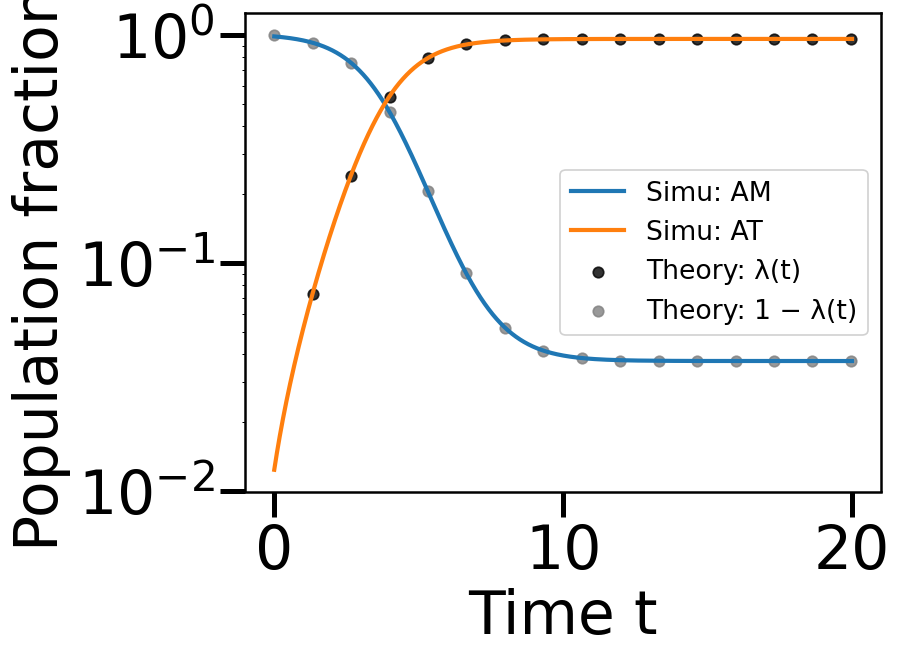

In [17]:
def solve_n0_n1(T, nu,Q=4, tol=1e-12):
    """
    Solve the 2x2 linear system for n0(t), n1(t) with arbitrary initial conditions.
    T : numpy array of times (shape (nt,))
    nu, Q : parameters
    n0_init, n1_init : initial values at t=0
    Returns (n0, n1) numpy arrays of same shape as T.
    """

    # constants
    Delta = np.sqrt((1.0 - nu)**2 + 4.0 * nu / Q)
    lam_p = (1.0 - nu + Delta) / 2.0
    lam_m = (1.0 - nu - Delta) / 2.0

    a11 = 1.0 - nu * (Q - 1.0) / Q
    a12 = nu / Q

    # eigenvector ratios v1/v0
    r_p = (lam_p - a11) / a12
    r_m = (lam_m - a11) / a12

    denom = (r_p - r_m)

    n0_init=r_p/(Q-1)/(1+r_p)
    n1_init=1-n0_init
    # handle generic (non-degenerate) case
    if abs(denom) > tol:
        C_p = (n1_init - r_m * n0_init) / denom
        C_m = (r_p * n0_init - n1_init) / denom

        n0 = C_p * np.exp(lam_p * T) + C_m * np.exp(lam_m * T)
        n1 = C_p * r_p * np.exp(lam_p * T) + C_m * r_m * np.exp(lam_m * T)

        return n0, n1

sol_0,sol_1=solve_n0_n1(x, nu)
lamb=sol_0/(sol_0+sol_1)
lamb=np.array([0]+list(lamb[:-1]))
# --- NICER PLOT WITH SCATTER ANALYTICAL CURVES ---

fig, ax = plt.subplots()

# --- Simulation curves (solid lines) ---
ax.plot(
    T[T < tau],
    res[T < tau, 0, 2] + res[T < tau, 0, 3] + res[T < tau, 0, 0],
    label="Simu: AM",
    linewidth=2.5,
)

ax.plot(
    T[T < tau],
    res[T < tau, 0, 1],
    label="Simu: AT",
    linewidth=2.5,
)

# --- Analytical curves (scatter points) ---
# Choose a stride to avoid too many markers
stride = max(1, len(x) // 15)   # ~150 markers max

ax.scatter(
    x[::stride],
    lamb[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory: λ(t)",
    alpha=0.8,
)

ax.scatter(
    x[::stride],
    (1 - lamb)[::stride],
    s=40,
    color="gray",
    label="Theory: 1 − λ(t)",
    alpha=0.8,
)

# Log scale on y-axis
ax.set_yscale("log")

# Labels
ax.set_xlabel("Time t")
ax.set_ylabel("Population fractions")

# Legend
ax.legend(
    loc="best",
    frameon=True,
    framealpha=0.9,
    fancybox=True,
    borderpad=0.4,
)

# Layout
plt.tight_layout()
plt.savefig('A_pop.svg')
plt.savefig('A_pop.png')


# III - Check the non A population

## 1) Check the TR=T, VR=M population

4.2924174e-05


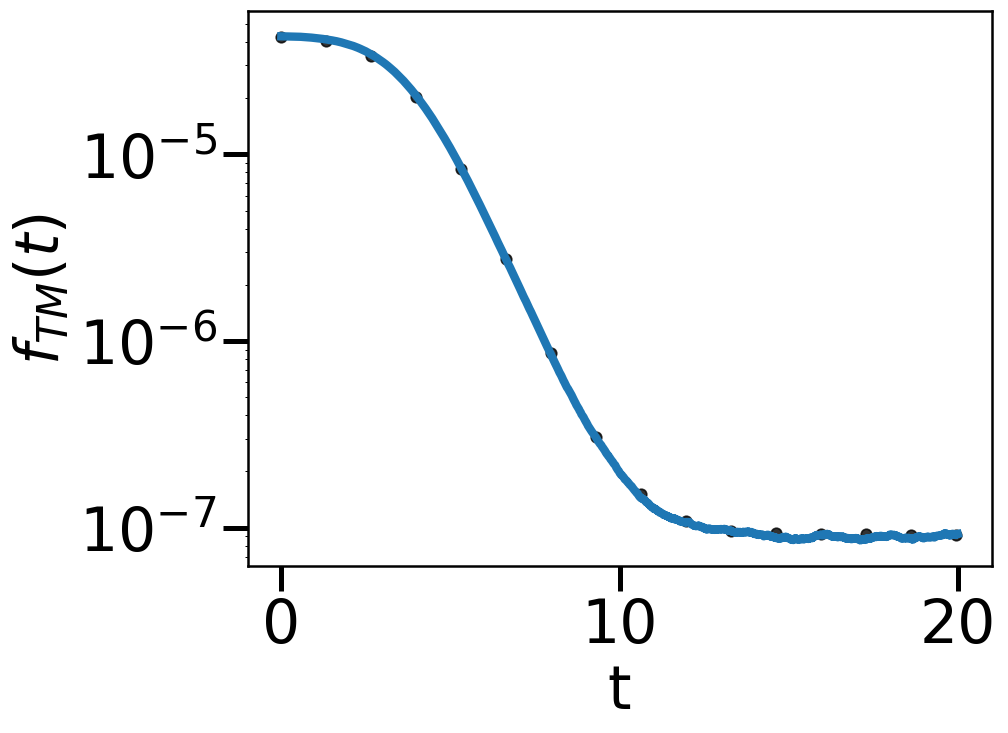

In [18]:
x=T[T<tau]
fTM=(res[:,1,0]+res[:,1,2]+res[:,1,3])[T<tau]
y_TM=fTM

Lamb=np.cumsum(lamb)*dt
C0=fTM[0]
C0=f[0,1,3]#
#C0=(fNT[-1])/(Q-2)
C0=b_star[3]
y_theo_TM=C0*np.exp(-nu*x-Lamb)+mu/Q*np.exp(-nu*x-Lamb)*np.cumsum(np.exp(nu*x+Lamb)*(1-lamb))*dt
print(fTM[0])
plt.plot(x,y_TM,label='Simu')
plt.scatter(x[::stride],y_theo_TM[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory",
    alpha=0.8,)

plt.semilogy()
plt.ylabel(r'$f_{TM}(t)$')
plt.xlabel('t')

plt.savefig('f_TM_pop.svg')
plt.savefig('f_TM_pop.png')


## 2) Check the TR=T, VR=T population

2.176515e-06


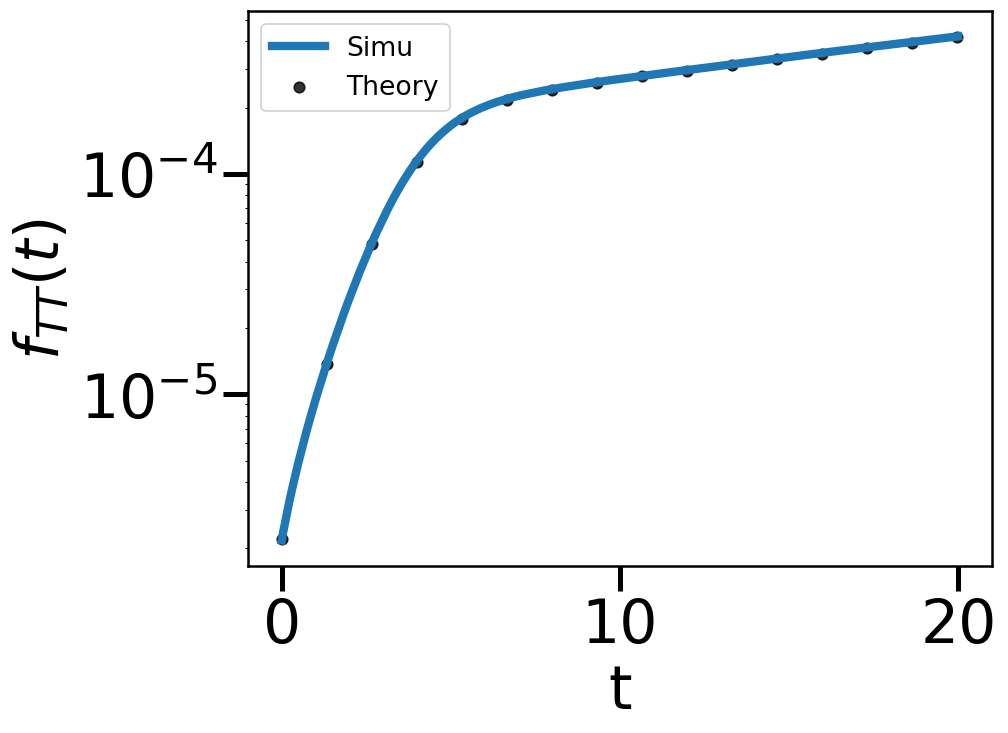

In [19]:
x=T[T<tau]
fTT=(res[:,1,1])[T<tau]

#fTT[0]=
y_TT=fTT
print(fTT[0])
#C0=frac[-1]*fNM[-1]
#C0=fNM[-1]/(Q-2)
C0=b_star[2]

#C0=fTT[0]
Lamb=np.cumsum(lamb)*dt
y_theo_TT=C0*np.exp(x-Lamb)+np.exp(x-Lamb)*np.cumsum(np.exp(-x+Lamb)*(mu/Q*lamb+nu*y_theo_TM))*dt

plt.plot(x,y_TT,label='Simu')
plt.scatter(x[::stride],y_theo_TT[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory",
    alpha=0.8,)
plt.semilogy()

plt.ylabel(r'$f_{TT}(t)$')
plt.xlabel('t')


plt.legend(
    loc="best",
    frameon=True,
    framealpha=0.9,
    fancybox=True,
    borderpad=0.4,
)

plt.savefig('f_TT_pop.svg')
plt.savefig('f_TT_pop.png')


## 3) Check the TR=N, VR=T population

6.325499999999999e-08


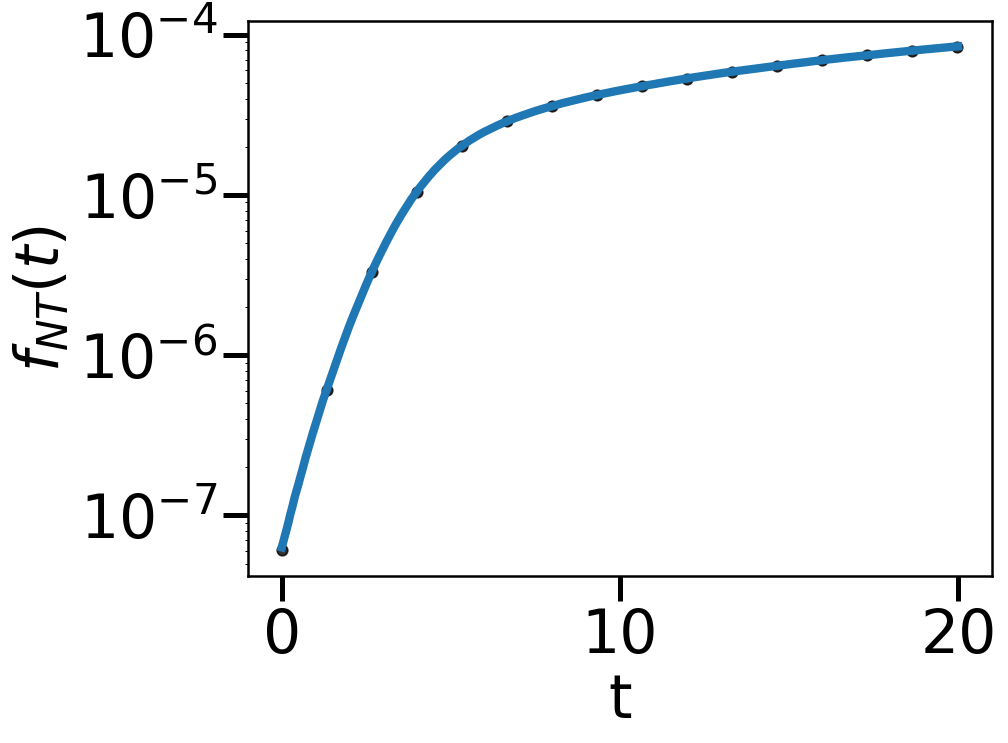

In [20]:
x=T[T<tau]
fNT=(res[:,2,1]+res[:,3,1])[T<tau]
y_NT=fNT
print(fNT[0])
C0=y_NT[0]
C0=y_TM[-1]/(Q-1)*(Q-2)
C0=b_star[1]

Lamb=np.cumsum(lamb)*dt
y_theo_NT=C0*np.exp(x-Lamb-nu*x)+np.exp(x-Lamb-nu*x)*np.cumsum(np.exp(-x+Lamb+nu*x)*mu/Q*(Q-2)*lamb)*dt

plt.plot(x,y_NT)
plt.scatter(x[::stride],y_theo_NT[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory",
    alpha=0.8,)
plt.semilogy()
plt.ylabel(r'$f_{NT}(t)$')
plt.xlabel('t')

plt.savefig('f_NT_pop.svg')
plt.savefig('f_NT_pop.png')

## 4) Check the TR=N, VR=M population

0.000459455352


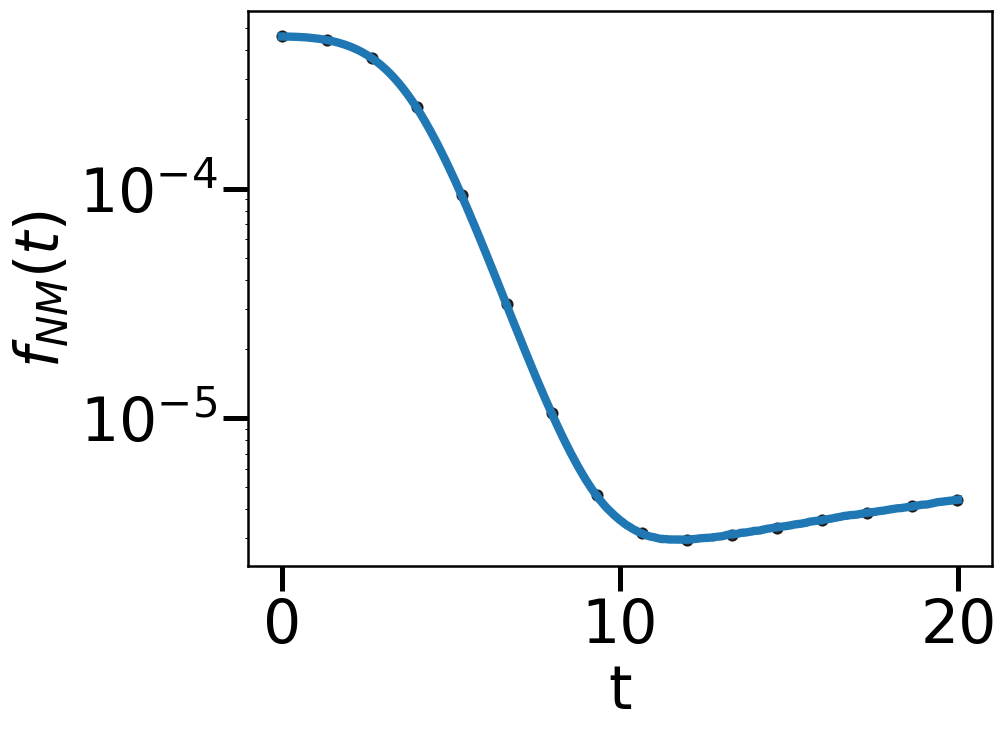

In [21]:
x=T[T<tau]
fNM=(res[:,2,0]+res[:,2,2]+res[:,2,3]+res[:,3,0]+res[:,3,2]+res[:,3,3])[T<tau]
y_NM=fNM
print(y_NM[0])
#C0=fTT[-1]+fTM[-1]/(Q-1)*(Q-2)+fNM[-1]/2+fNT[-1]/2
C0=b_star[0]

Lamb=np.cumsum(lamb)*dt
y_theo_NM=C0*np.exp(-Lamb)+np.exp(-Lamb)*np.cumsum(np.exp(Lamb)*(mu/Q*(Q-2)*(1-lamb)+nu*y_theo_NT))*dt

plt.plot(x,y_NM)
plt.scatter(x[::stride],y_theo_NM[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory",
    alpha=0.8,)
plt.semilogy()
plt.ylabel(r'$f_{NM}(t)$')
plt.xlabel('t')

plt.savefig('f_NM_pop.svg')
plt.savefig('f_NM_pop.png')

## 5) Check the total non A population

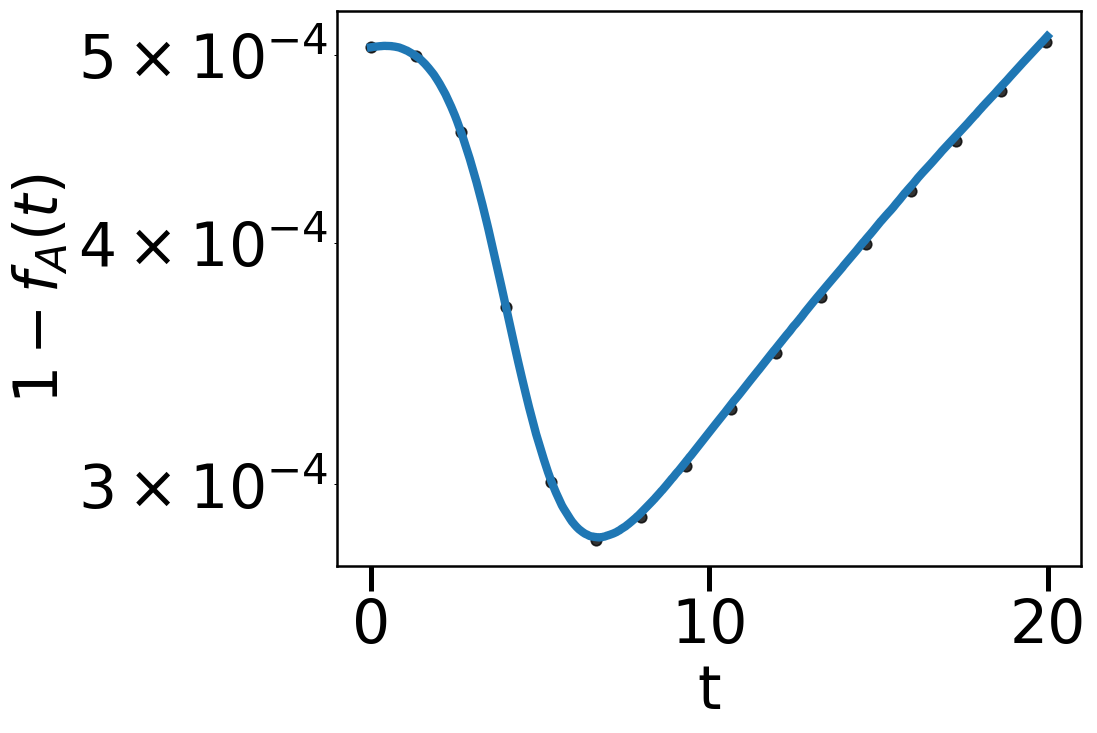

In [22]:
fA=np.sum(res[:,0,:],axis=1)
f_non_A=1-fA[T<tau]
x=T[T<tau]
f_theo_non_A=y_theo_TM +y_theo_TT +y_theo_NT + y_theo_NM 

plt.plot(x,f_non_A)
plt.scatter(x[::stride],f_theo_non_A[::stride],
    s=40,                   # marker size
    color="k",
    label="Theory",
    alpha=0.8,)

plt.ylabel(r'$1-f_{A}(t)$')
plt.xlabel('t')
plt.semilogy()
plt.savefig('f_notA_pop.svg')
plt.savefig('f_notA_pop.png')

# Non A fraction 

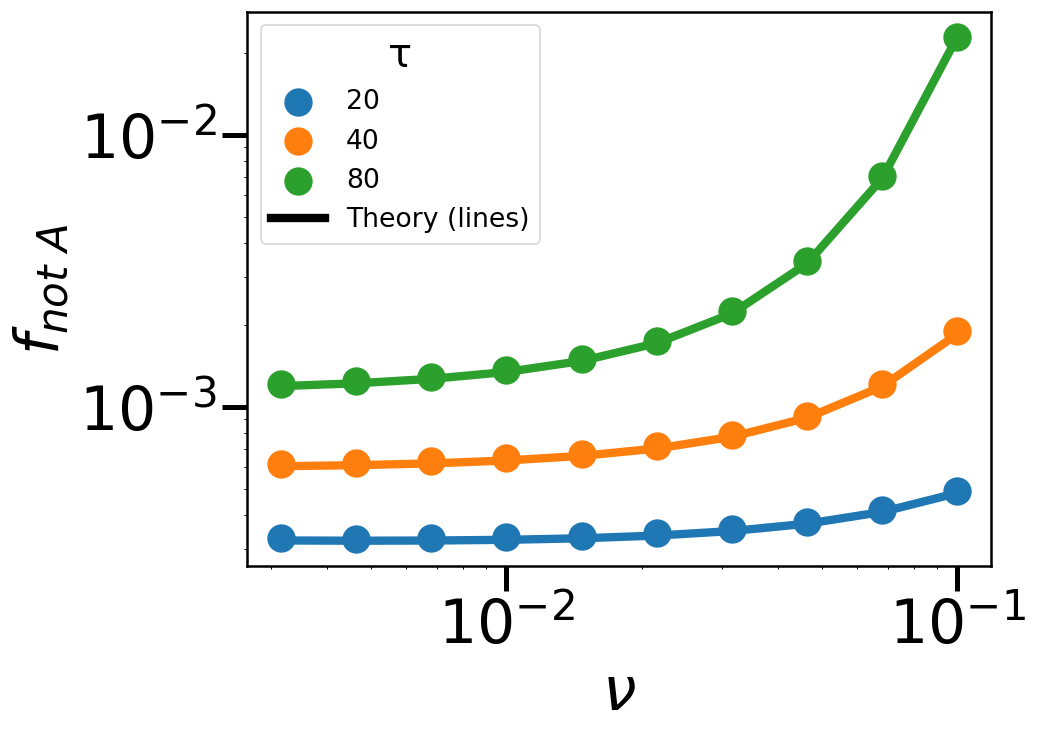

In [23]:
def compute_lambda(dt,nu,tau,Q):
    x=np.arange(int(tau/dt))*dt
    
    def solve_n0_n1(T, nu,Q=4, tol=1e-12):
        """
        Solve the 2x2 linear system for n0(t), n1(t) with arbitrary initial conditions.
        T : numpy array of times (shape (nt,))
        nu, Q : parameters
        n0_init, n1_init : initial values at t=0
        Returns (n0, n1) numpy arrays of same shape as T.
        """
    
        # constants
        Delta = np.sqrt((1.0 - nu)**2 + 4.0 * nu / Q)
        lam_p = (1.0 - nu + Delta) / 2.0
        lam_m = (1.0 - nu - Delta) / 2.0
    
        a11 = 1.0 - nu * (Q - 1.0) / Q
        a12 = nu / Q
    
        # eigenvector ratios v1/v0
        r_p = (lam_p - a11) / a12
        r_m = (lam_m - a11) / a12
    
        denom = (r_p - r_m)
    
        n0_init=r_p/(Q-1)/(1+r_p)
        n1_init=1-n0_init
        # handle generic (non-degenerate) case
        if abs(denom) > tol:
            C_p = (n1_init - r_m * n0_init) / denom
            C_m = (r_p * n0_init - n1_init) / denom
    
            n0 = C_p * np.exp(lam_p * T) + C_m * np.exp(lam_m * T)
            n1 = C_p * r_p * np.exp(lam_p * T) + C_m * r_m * np.exp(lam_m * T)
    
            return n0, n1
    
    sol_0,sol_1=solve_n0_n1(x, nu)
    lamb=sol_0/(sol_0+sol_1)
    return lamb



def compute_fractions_CF(lamb, dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM):
    """
    Compute final values of the fractions f_NM, f_NT, f_TT, f_TM
    using the integral formulas with exponentials inside the integral.
    """

    lamb = np.asarray(lamb)
    N = len(lamb)
    t = np.arange(N) * dt
    Lambda = np.cumsum(lamb) * dt

    # ---------------- f_TM ----------------
    I_TM = np.zeros(N)
    for i in range(1, N):
        # exponential factor inside the sum
        I_TM[i] = np.sum(np.exp(nu * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * (1 - lamb[:i])) * dt
    f_TM = f0_TM * np.exp(-nu*t - Lambda) + (mu/Q) * I_TM

    # ---------------- f_NT ----------------
    I_NT = np.zeros(N)
    for i in range(1, N):
        I_NT[i] = np.sum(np.exp((-1+nu) * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * lamb[:i]) * dt
    f_NT = f0_NT * np.exp((1-nu)*t - Lambda) + (mu*(Q-2)/Q) * I_NT

    # ---------------- f_TT ----------------
    I_TT = np.zeros(N)
    for i in range(1, N):
        I_TT[i] = np.sum(np.exp((-t[:i] + t[i]) + (Lambda[:i] - Lambda[i])) * (mu/Q*lamb[:i] + nu*f_TM[:i])) * dt
    f_TT = f0_TT * np.exp(t - Lambda) +  I_TT

    # ---------------- f_NM ----------------
    I_NM = np.zeros(N)
    for i in range(1, N):
        I_NM[i] = np.sum(np.exp(Lambda[:i] - Lambda[i]) * (mu*(Q-2)/Q*(1-lamb[:i]) + nu*f_NT[:i])) * dt
    f_NM = f0_NM * np.exp(-Lambda) +  I_NM

    return f_NM[-1], f_NT[-1], f_TT[-1], f_TM[-1]


def compute_the_CI(lamb,dt,mu,nu,Q):
    c = np.array( compute_fractions_CF(lamb, dt, mu, nu, Q, 0,0,0,0) )

    M = np.zeros((4,4))
    
    for i in range(4):
        e = np.zeros(4)
        e[i] = 1.0
        M[:,i] = np.array( compute_fractions_CF(lamb, dt, mu, nu, Q, *e) ) - c
    
    R = np.array([
        [1/(Q-2), 1/(Q-2), 1,           (Q-2)/(Q-1)],
        [0,       0,       0,           (Q-2)/(Q-1)],
        [1/(Q-2), 0,       0,           0],
        [0,       1/(Q-2), 0,           0]
    ], dtype=float)
    
    A = R @ M
    d = R @ c
    
    I = np.eye(4)
    b_star = np.linalg.solve(I - A, d)
    return b_star

def compute_fractions_whole(lamb,
    dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM):
    """
    Compute final values of the fractions f_NM, f_NT, f_TT, f_TM
    using the integral formulas with exponentials inside the integral.
    """

    lamb = np.asarray(lamb)
    N = len(lamb)
    t = np.arange(N) * dt
    Lambda = np.cumsum(lamb) * dt

    # ---------------- f_TM ----------------
    I_TM = np.zeros(N)
    for i in range(1, N):
        # exponential factor inside the sum
        I_TM[i] = np.sum(np.exp(nu * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * (1 - lamb[:i])) * dt
    f_TM = f0_TM * np.exp(-nu*t - Lambda) + (mu/Q) * I_TM

    # ---------------- f_NT ----------------
    I_NT = np.zeros(N)
    for i in range(1, N):
        I_NT[i] = np.sum(np.exp((-1+nu) * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * lamb[:i]) * dt
    f_NT = f0_NT * np.exp((1-nu)*t - Lambda) + (mu*(Q-2)/Q) * I_NT

    # ---------------- f_TT ----------------
    I_TT = np.zeros(N)
    for i in range(1, N):
        I_TT[i] = np.sum(np.exp((-t[:i] + t[i]) + (Lambda[:i] - Lambda[i])) * (mu/Q*lamb[:i] + nu*f_TM[:i])) * dt
    f_TT = f0_TT * np.exp(t - Lambda) +  I_TT

    # ---------------- f_NM ----------------
    I_NM = np.zeros(N)
    for i in range(1, N):
        I_NM[i] = np.sum(np.exp(Lambda[:i] - Lambda[i]) * (mu*(Q-2)/Q*(1-lamb[:i]) + nu*f_NT[:i])) * dt
    f_NM = f0_NM * np.exp(-Lambda) +  I_NM

    return f_NM, f_NT, f_TT, f_TM

def compute_nonA_fraction(tau,dt,mu, nu,Q): #sums all frequencies corresponding to non A sequences
    lamb=compute_lambda(dt,nu,tau,Q)
    [f0_NM, f0_NT, f0_TT, f0_TM]=compute_the_CI(lamb,dt,mu,nu,Q)
    [f_NM, f_NT, f_TT, f_TM]=compute_fractions_whole(lamb,dt, mu, nu, Q,f0_NM, f0_NT, f0_TT, f0_TM)
    return np.mean(f_NM+f_NT+f_TT+f_TM)

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.lines as mlines

for tau in [20, 40, 80]:
    fnon_A = []
    fnon_A_theo = []
    dt = 5e-2
    mu = 1e-5
    Q = 4
    
    nu_lis = np.logspace(-2.5, -1, 10)
    for nu in nu_lis:
        res, AvH = compete_four_pops_multinomial(
            tau, mu, nu, dt, PopSize=10**12, steps=int(tau/dt*10)
        )
        fnon_A.append(1 - np.mean(np.sum(res[:, 0, :], axis=1)))
        fnon_A_theo.append(compute_nonA_fraction(tau, dt, mu, nu, Q))

    # Your original line and point plotting
    plt.plot(nu_lis, fnon_A_theo)
    plt.scatter(nu_lis, fnon_A, label=f'{tau}')

plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_{not~A}$')
plt.semilogx()
plt.semilogy()

# ---- Add theory legend entry at the bottom ----
theory_proxy = mlines.Line2D([], [], color='black', label='Theory (lines)')

# Existing handles
handles, labels = plt.gca().get_legend_handles_labels()

# Append the theory entry at the bottom
handles = handles + [theory_proxy]
labels = labels + ['Theory (lines)']

plt.legend(handles, labels, title='τ')

plt.savefig('fnonA_exact.svg')
plt.savefig('fnonA_exact.png')


# Fraction of non A as function of $\mu$, several $\nu$

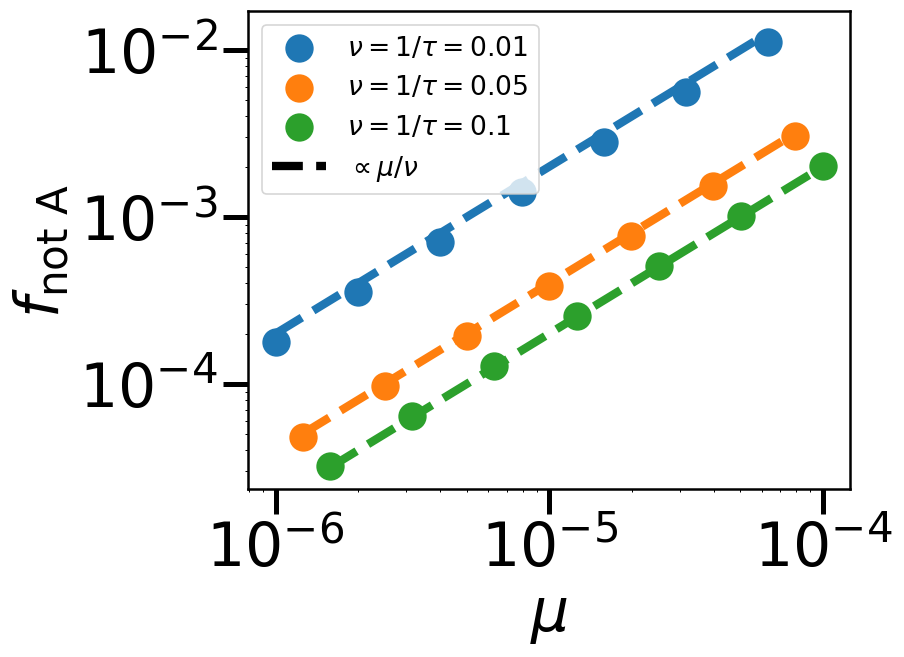

In [24]:
from joblib import Parallel, delayed
import numpy as np
import matplotlib.pyplot as plt

dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A(mu, nu):
    tau = 1 / nu
    steps = int(tau/dt*10)
    freq, _ = compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=PopSize, steps=steps)
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))

nu_list = [1e-2, 5e-2, 1e-1]

colors = plt.cm.viridis(np.linspace(0, 1, len(nu_list)))  # for scatter + dotted lines



index = 0
already_added_line_legend = False

for i, nu in enumerate(nu_list):
    mu_lis = np.logspace(-6, -4, 21)[index::3]
    index += 1

    # Parallel simulation
    f_not_A = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A)(mu, nu) for mu in mu_lis
    )
    f_not_A = np.array(f_not_A)

    # --- scatter ---
    plt.scatter(mu_lis, f_not_A,
                label=rf"$\nu=1/\tau={nu:g}$")

    # --- dotted line ---
    plt.plot(mu_lis,
             mu_lis/nu * 2,
             '--'
    )

    # Only **one** legend entry for the dotted lines (in black)
if not already_added_line_legend:
        plt.plot([], [], 'k--', label=r'$\propto \mu/\nu$')
        already_added_line_legend = True


plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$\mu$")
plt.ylabel(r"$f_{\text{not A}}$")

plt.legend()
plt.tight_layout()
plt.savefig("nutau_1.svg")
plt.savefig("nutau_1.png")
plt.show()


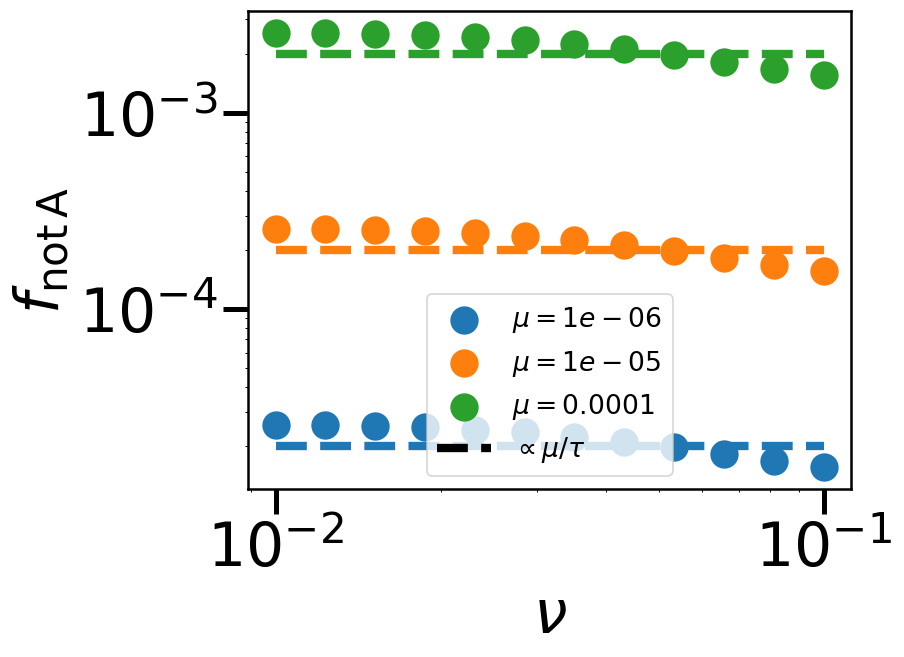

In [25]:
from joblib import Parallel, delayed
import numpy as np
import matplotlib.pyplot as plt

dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A_nu(nu, mu, tau):
    steps = int(tau/dt*10)
    freq, AvH = compete_four_pops_multinomial(
        tau, mu, nu, dt, PopSize=PopSize, steps=steps
    )
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))


# ---------------------- Dependence on ν (μ fixed) ----------------------
mus = [1e-6, 1e-5, 1e-4]


nu_lis = np.logspace(-2, -1, 12)
tau = 5   # fixed tau

for mu, col in zip(mus, colors):

    # ---- Parallel computation over nu ----
    f_not_A_nu = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A_nu)(nu, mu, tau) for nu in nu_lis
    )
    f_not_A_nu = np.array(f_not_A_nu)

    # Numerical simulation points
    plt.scatter(nu_lis, f_not_A_nu,
                label=rf"$\mu={mu:g}$")

    # Analytical expectation in the *same* color
    pred = (mu*tau) * np.ones_like(nu_lis)*4
    plt.plot(nu_lis, pred, '--')


# Add a single black dashed for legend clarity
plt.plot([], [], '--k', label=r'$\propto \mu/\tau$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_\mathrm{not\,A}$')

plt.legend()
plt.tight_layout()
plt.savefig("nutau_small.svg")
plt.savefig("nutau_small.png")
plt.show()


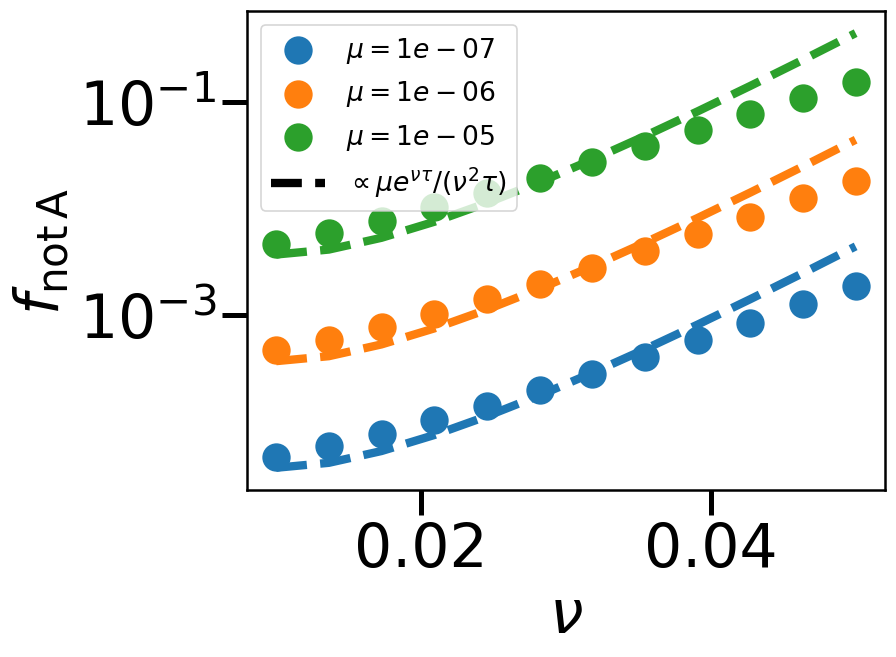

In [26]:
from joblib import Parallel, delayed
import numpy as np
import matplotlib.pyplot as plt

dt = 1e-1
Q = 4
PopSize = 10**12

def compute_f_not_A_nu(nu, mu, tau):
    steps = int(tau/dt*10)
    freq, AvH = compete_four_pops_multinomial(
        tau, mu, nu, dt, PopSize=PopSize, steps=steps
    )
    return np.mean(1 - np.sum(freq[:,0,:], axis=1))


# ---------------------- Dependence on ν (μ fixed) ----------------------
mus = [1e-7, 1e-6, 1e-5]
colors = ["C0", "C1", "C2"]

plt.figure()

nu_lis = np.linspace(0.01,0.05, 12)
tau = 200   # fixed tau

for mu, col in zip(mus, colors):

    # ---- Parallel computation over nu ----
    f_not_A_nu = Parallel(n_jobs=-1)(
        delayed(compute_f_not_A_nu)(nu, mu, tau) for nu in nu_lis
    )
    f_not_A_nu = np.array(f_not_A_nu)

    # Numerical simulation points
    plt.scatter(nu_lis, f_not_A_nu, color=col,
                label=rf"$\mu={mu:g}$")

    # Analytical expectation in the *same* color
    pred = (mu/nu_lis**2/tau) * np.exp(nu_lis*tau)
    plt.plot(nu_lis, pred, '--', color=col)


# Add a single black dashed for legend clarity
plt.plot([], [], '--k', label=r'$\propto \mu e^{\nu \tau}/(\nu^2\tau)$')

#plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_\mathrm{not\,A}$')
plt.tight_layout()
plt.legend()

plt.savefig("nutau_big.svg")
plt.savefig("nutau_big.png")

plt.show()
